## Exercise for tutorial "Physical attacks: Power analysis against cryptographic devices" at ICECS 2026
*Authors: Martin Schmid (University of Passau), Prof. Dr.-Ing. Elif Bilge Kavun (Technical University Dresden)*

---

### Overview

You are given power traces recorded from a hardware AES-128 core running on a CW305 FPGA target, captured with a ChipWhisperer-Lite. Your job is to recover the secret key from these traces alone, using Correlation Power Analysis.

### Information: The hardware under attack

The target is an **iterative** AES-128 hardware implementation: one full round is applied per clock cycle and written back into the state register. Everything in the diagram lives inside the cryptographic device and draws current from the power supply, which is recorded in the given power traces.

To record the power traces, we let the device encrypt a lot of different plaintexts without knowing them. We do however know the ciphertext output of the device.

The key schedule and register generates and stores the round keys (10 of them, each for one round) and is not of interest for our attack, its computation does not depend on the changing input. Instead, the point of attack will be the power consumption of the combinational logic within the round and the state register.

<p align="center">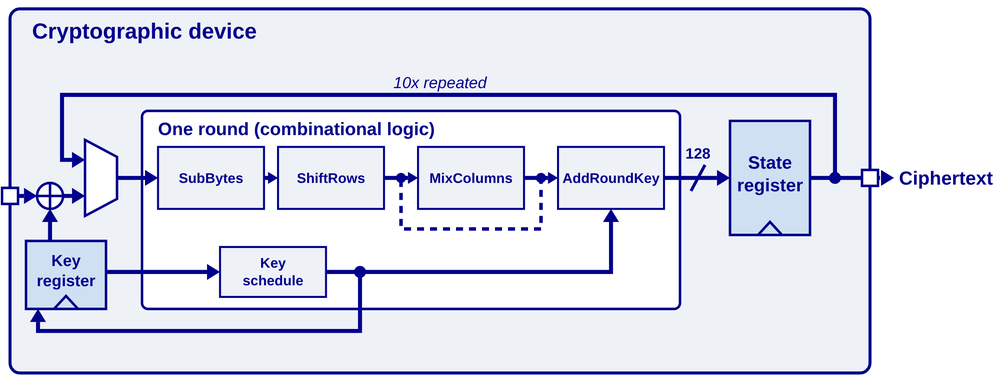</p>

### Background: AES basics

AES-128 (variant of the Rijndael cipher) transforms a 128-bit (=16-byte) state over 10 consecutive rounds. The state $[b_0, b_1, \dots, b_{15}]$ is visualized as a 4x4 matrix, where each of the 16 bytes in the 128-bit state are one matrix entry. The matrix is ordered column-wise, so the second byte in the state $b_1$ is in the first column and second row.

<p align="center">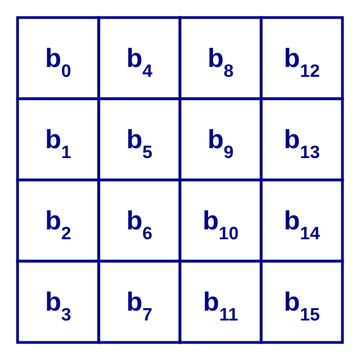</p>

One round takes as input the current 16-byte state and a 16-byte round key, applies four operations and outputs the next state. Apart from the changing inputs, all rounds execute completely identical operations, with two exceptions:
- Before the first round starts, an the AddRoundKey operation is applied with the input key.
- In the last round, the MixColumns operation is skipped.

One round comprises the following four operations:

- **SubBytes**: A fixed, non-linear byte substitution (the S-box),
applied to each byte on its own. You can think of it like a vending machine. The bytes/boxes do not interact with each other, each is processed individually.

<p align="center">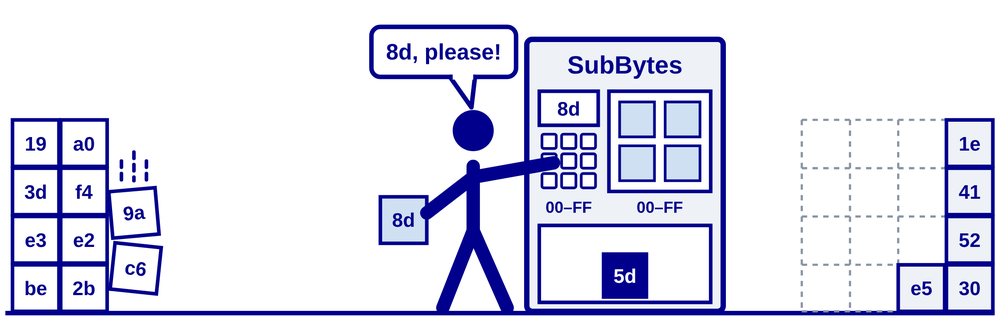</p>

- **ShiftRows**: Cyclically shifts the rows of the state. The bytes/boxes do not interact with each other, only each one's position is changed.

<p align="center">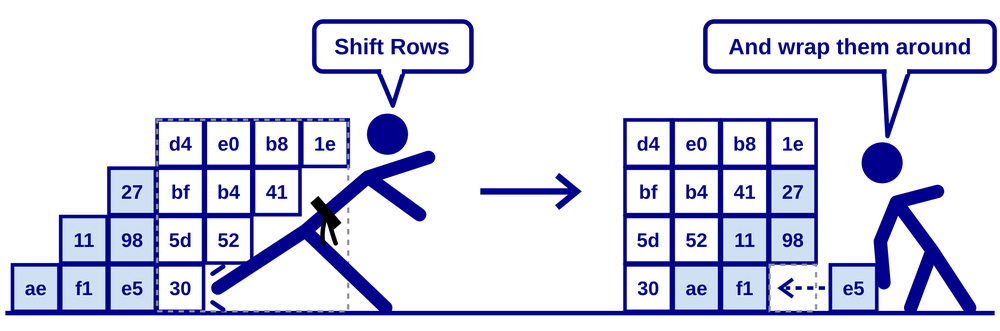</p>

- **MixColumns**: Mixes the four bytes *within each column*. You can imagine that four boxes are put into a shredder, combined and repacked into new four boxes. This means, the bytes/boxes interact with each other.
<p align="center">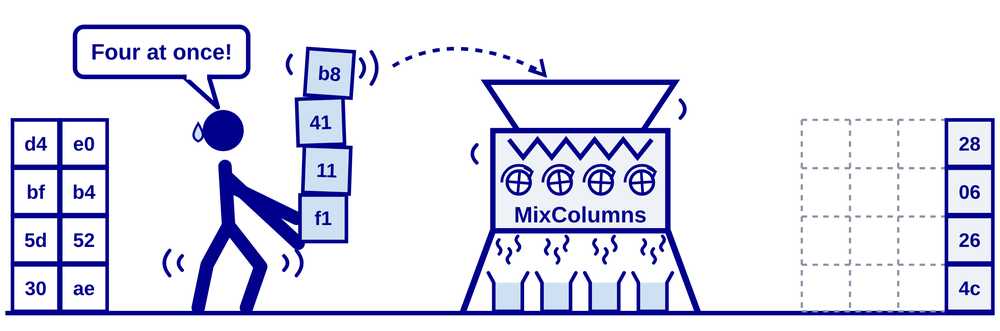</p>

- **AddRoundKey**: XORs the current round key ($rk_0,\dots,rk_{10}$) into the state, one byte at a time. Here, bytes/boxes do not interact with each other.

<p align="center">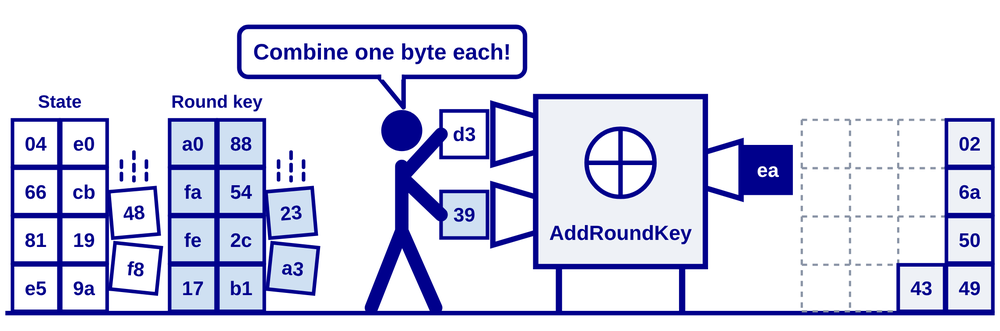</p>


### Reminder: Differential Power Analysis

#### Procedure
1. Collect data–trace pairs on many different inputs.
2. Choose a *power model* and an *intermediate value function* $f(d, k)$ that is
   - non-linear in the data $d$, and
   - dependent on only a small chunk $k$ of the key.
3. *Divide* — for every possible value $x$ of a fixed small key part $k$:
   - compute the intermediate values $f(d_j, x)$ and their associated power values for all data $d_j$
   - find the $x$ whose power values correlate the most with the traces.
4. *Conquer* — repeat step 3 for every small part of the key individually.

#### Visualized steps

<p align="center">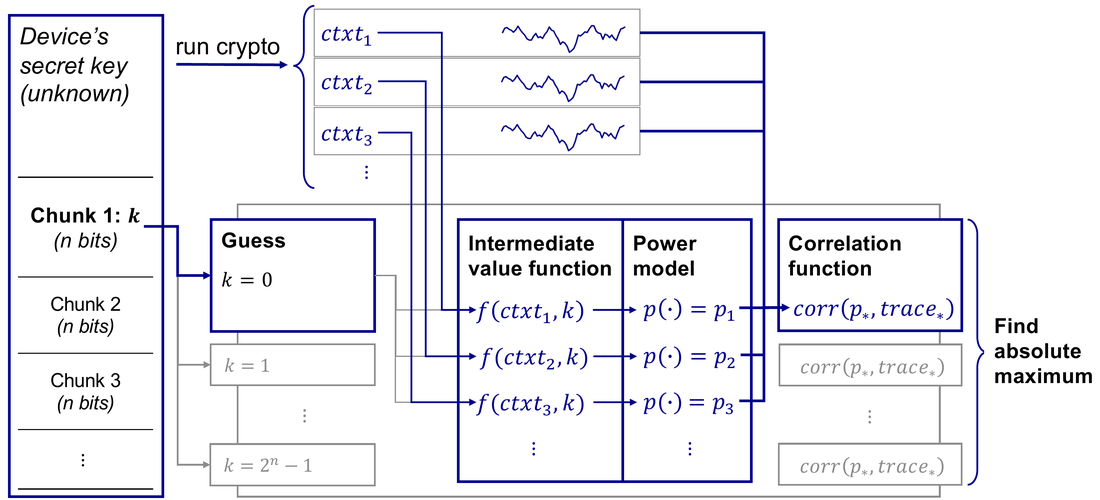</p>

---

### Task Description

#### Given
- 5000 power traces stored in a numpy array, together with the corresponding ciphertext outputs.
- Helper functions for
  - plotting a few traces and determining the active time window
  - loading the traces (trimmed to the selected active region) together with the corresponding list of ciphertexts.
- The actual last-round key that was used in the AES core, so you can check your result at the end.

#### Task
1. **Visually determine the active window** by looking at the traces, and trim to it.
2. **Finish the code skeleton** by implementing the *intermediate value function*, the *power model*, the *correlation function* and finding the maximum.
3. **Extract the key** and compare it to the given solution.

#### Hints
- **Byte ordering.** The first index of a byte array is the top-left matrix element, then  going column-wise (column-major), i.e. $b_0 \dots b_{15}$
- **Intermediate value function.** Apply one reversed round to each ciphertext byte at the targeted key index to obtain its corresponding round-9 state byte: `st9 = INV_SBOX[ct[i] ^ x]`.
- **Power model.** Use the Hamming distance between that round-9 state byte and the ciphertext byte at the same register position: `HD = HW[st9 ^ ct[INV_SHIFTROWS[i]]]`.
- **Correlation.** Use the Pearson correlation (implemented in numpy).

---
## Code

Adjust the code in the lines marked with TODO. The first two codeblocks are just used for setup and introducing helper functions - they require no change.


In [ ]:
#@title 0 - Setup: Fetch traces from repository (simply run once) { display-mode: "form" }
%pip install -q numpy matplotlib
!wget -q https://raw.githubusercontent.com/martinowiczzz/icecs26-power-analysis-tutorial/main/traces.zip
!unzip -o -q traces.zip        # creates traces/traces.npy and traces/textout.npy

### 1 - Read the traces from the downloaded files (run once)

Further, initializes AES helper functions like S-Box and ShiftRows, and their inverse. Simply run this block, no need to adjust.

In [ ]:
import numpy as np, glob

_d = "traces"
traces_full = np.load(glob.glob(_d + "/*traces.npy")[0]).astype(np.float64)
ciphertext_array = np.load(glob.glob(_d + "/*textout.npy")[0]).astype(np.uint8)

# the traces file has one extra trailing row — align it to the ciphertexts
N_TRACES    = ciphertext_array.shape[0]        # 5000
traces_full = traces_full[:N_TRACES]      # (5000, 129)
N_SAMPLES   = traces_full.shape[1]        # 129

print("traces:", traces_full.shape, " ciphertexts:", ciphertext_array.shape)

# ---- GIVEN constants --------------------------------------------------------
# AES S-box and its inverse
SBOX = np.array([
    0x63,0x7c,0x77,0x7b,0xf2,0x6b,0x6f,0xc5,0x30,0x01,0x67,0x2b,0xfe,0xd7,0xab,0x76,
    0xca,0x82,0xc9,0x7d,0xfa,0x59,0x47,0xf0,0xad,0xd4,0xa2,0xaf,0x9c,0xa4,0x72,0xc0,
    0xb7,0xfd,0x93,0x26,0x36,0x3f,0xf7,0xcc,0x34,0xa5,0xe5,0xf1,0x71,0xd8,0x31,0x15,
    0x04,0xc7,0x23,0xc3,0x18,0x96,0x05,0x9a,0x07,0x12,0x80,0xe2,0xeb,0x27,0xb2,0x75,
    0x09,0x83,0x2c,0x1a,0x1b,0x6e,0x5a,0xa0,0x52,0x3b,0xd6,0xb3,0x29,0xe3,0x2f,0x84,
    0x53,0xd1,0x00,0xed,0x20,0xfc,0xb1,0x5b,0x6a,0xcb,0xbe,0x39,0x4a,0x4c,0x58,0xcf,
    0xd0,0xef,0xaa,0xfb,0x43,0x4d,0x33,0x85,0x45,0xf9,0x02,0x7f,0x50,0x3c,0x9f,0xa8,
    0x51,0xa3,0x40,0x8f,0x92,0x9d,0x38,0xf5,0xbc,0xb6,0xda,0x21,0x10,0xff,0xf3,0xd2,
    0xcd,0x0c,0x13,0xec,0x5f,0x97,0x44,0x17,0xc4,0xa7,0x7e,0x3d,0x64,0x5d,0x19,0x73,
    0x60,0x81,0x4f,0xdc,0x22,0x2a,0x90,0x88,0x46,0xee,0xb8,0x14,0xde,0x5e,0x0b,0xdb,
    0xe0,0x32,0x3a,0x0a,0x49,0x06,0x24,0x5c,0xc2,0xd3,0xac,0x62,0x91,0x95,0xe4,0x79,
    0xe7,0xc8,0x37,0x6d,0x8d,0xd5,0x4e,0xa9,0x6c,0x56,0xf4,0xea,0x65,0x7a,0xae,0x08,
    0xba,0x78,0x25,0x2e,0x1c,0xa6,0xb4,0xc6,0xe8,0xdd,0x74,0x1f,0x4b,0xbd,0x8b,0x8a,
    0x70,0x3e,0xb5,0x66,0x48,0x03,0xf6,0x0e,0x61,0x35,0x57,0xb9,0x86,0xc1,0x1d,0x9e,
    0xe1,0xf8,0x98,0x11,0x69,0xd9,0x8e,0x94,0x9b,0x1e,0x87,0xe9,0xce,0x55,0x28,0xdf,
    0x8c,0xa1,0x89,0x0d,0xbf,0xe6,0x42,0x68,0x41,0x99,0x2d,0x0f,0xb0,0x54,0xbb,0x16,
], dtype=np.uint8)
INV_SBOX = np.zeros(256, dtype=np.uint8)
INV_SBOX[SBOX] = np.arange(256, dtype=np.uint8)

# Hamming weight of every byte value (0..255)
HW = np.array([bin(x).count("1") for x in range(256)], dtype=np.uint8)

# Inverse ShiftRows (column-major): for state byte i, the register position of the
# ciphertext byte it pairs with in the last-round Hamming-distance model.
INV_SHIFTROWS = np.array([0, 5, 10, 15, 4, 9, 14, 3, 8, 13, 2, 7, 12, 1, 6, 11])

# The ACTUAL last-round (round-10) key -- only for checking your result at the end.
ACTUAL_LAST_ROUND_KEY = [0xd0, 0x14, 0xf9, 0xa8, 0xc9, 0xee, 0x25, 0x89,
                         0xe1, 0x3f, 0x0c, 0xc8, 0xb6, 0x63, 0x0c, 0xa6]

### 2 · Plot the traces, find the window of interest and load the trimmed traces into memory
Play around with the variables `T_START`/`T_END` to shade a candidate active region in the plotted power trace. You should be able to visually determine the active region pretty easily (the trace capture runs longer than the algorithm). It is okay, if your active window includes some points before and after the algorithm runs, trimming is only applied for faster processing.

In [ ]:
import matplotlib.pyplot as plt

def plot_traces(n_traces, t_start, t_end):
    """Plot the first `n` traces. Start/end (sample indices) are start and
    end point for the shaded area, so you can adjust them to
    the window of interest."""
    plt.figure(figsize=(12, 4))
    for i in range(n_traces):
        plt.plot(traces_full[i], lw=0.6)
    plt.axvspan(t_start, t_end, color="orange", alpha=0.20,
                    label=f"active region [{t_start}:{t_end}]")
    plt.legend(loc="upper right")
    plt.xlabel("sample index"); plt.ylabel("power")
    plt.title(f"first {n_traces} traces"); plt.tight_layout(); plt.show()

T_START =   0 # PLAY AROUND WITH THIS VALUE [Hint: between 0 and 10]
T_END   = 128 # PLAY AROUND WITH THIS VALUE [Hint: between 50 and 128]
plot_traces(n_traces=15, t_start=T_START, t_end=T_END)

trace_array = traces_full[:, T_START:T_END]
print("trimmed traces:", trace_array.shape, " ciphertexts:", ciphertext_array.shape)


### 3 - The DPA attack
The loops over the **16 key-byte positions** and their **256 candidate values** are already
here. Implement the `TODO`s: the intermediate value, the power
model.

In [ ]:
def pearson(power_values, traces):
    """Pearson correlation of the hypothesis against every time sample.
       power_values: (N_TRACES,)              one predicted value per trace
       traces      : (N_TRACES, n_samples)    measured power per trace, per sample
       returns     : (n_samples,)             |correlation| at each sample
    """
    power_values_centered = power_values - power_values.mean()
    traces_centered = traces - traces.mean(axis=0)
    numerator = (traces_centered * power_values_centered[:, None]).sum(axis=0)
    denominator = np.sqrt((power_values_centered**2).sum() * (traces_centered**2).sum(axis=0))
    return np.abs(numerator / denominator)

recovered_key = [None] * 16

for byte_idx in range(16):
    best_score = -1.0
    best_guess = None
    ct_i_array    = ciphertext_array[:, byte_idx]
    # Note: ct_i is not one single byte but a list of the byte at index byte_idx across all ciphertexts

    # TODO: Determine the ciphertext bytes at the same position as the round 9 state byte
    #      and store in ct_same_position_array
    # Hint: Inverse ShiftRows, function exists
    ct_same_position_array = None

    for guess in range(256):
        # TODO 1: Compute intermediate values based on ct_i_array and guess
        # Hint: Numpy allows operations like (array ^ value), where it the XORs every
        #       element in the array with the value, returning the modified array.

        # TODO 2: Compute power model value based on round 9 state and ct_same_position.
        # Hint: "Hamming distance(a,b)" is the same as "Hamming weight(a ^ b)"

        # TODO 3: Determine correlation between power value array and trace array
        corr = np.zeros(trace_array.shape[1]) # Overwrite this, only initialized to something
                                         # so that skeleton code runs

        score = corr.max()
        if score > best_score:
            best_score, best_guess = score, int(guess)

    recovered_key[byte_idx] = best_guess
    print(f"byte {byte_idx:2d}: " + (f"0x{best_guess:02x}" if best_guess is not None else "--"))

print("recovered :", [f"0x{b:02x}" for b in recovered_key] if None not in recovered_key else recovered_key)
print("actual    :", [f"0x{b:02x}" for b in ACTUAL_LAST_ROUND_KEY])

match = recovered_key == ACTUAL_LAST_ROUND_KEY
print("\n*** FULL MATCH — key recovered! ***" if match
      else "\nnot yet fully matching.")

<details>
<summary><b>▶ Show solution (click to expand)</b></summary>

<pre><code>recovered_key = [None] * 16
for byte_idx in range(16):
    best_score = -1.0
    best_guess = None
    ct_i_array = ciphertext_array[:, byte_idx]
    ct_same_position_array = ciphertext_array[:, INV_SHIFTROWS[byte_idx]]
    
    for guess in range(256):
        st9 = INV_SBOX[ct_i_array ^ guess]
        power_value_array = HW[st9 ^ ct_same_position_array].astype(np.float64)
        corr = pearson(power_value_array, trace_array)
  
        score = corr.max()
        if score > best_score:
            best_score, best_guess = score, int(guess)

    recovered_key[byte] = best_guess
    print(f"byte {byte:2d}: 0x{best_guess:02x}")

print("\nrecovered key:", recovered_key)
</code></pre>

</details>